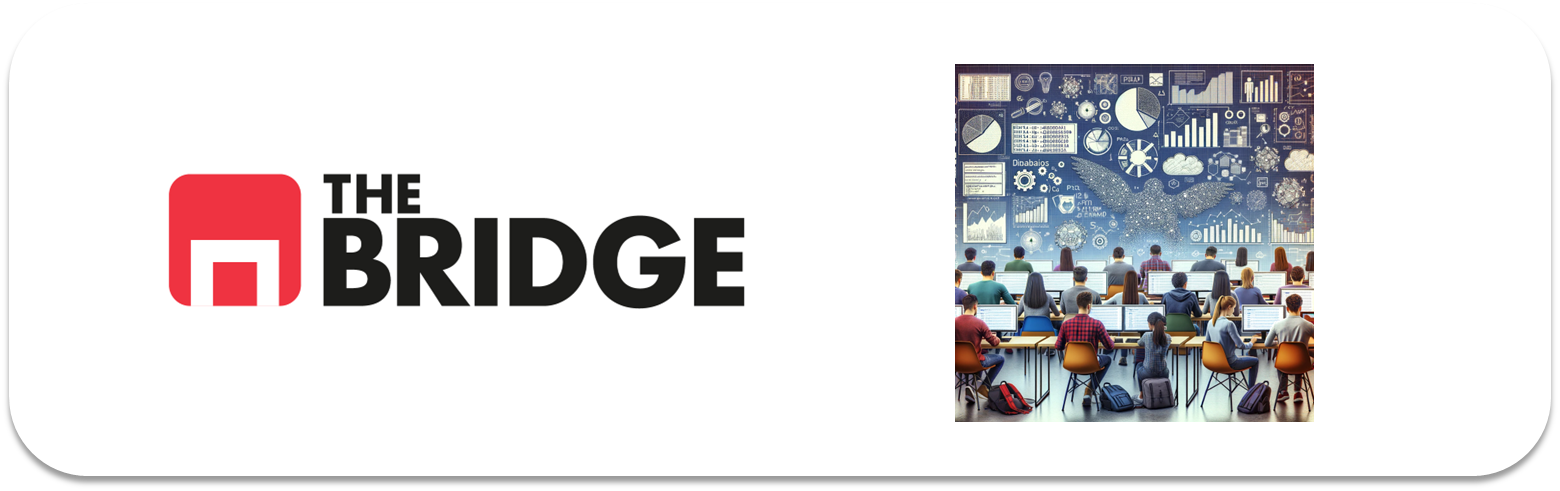

# Pipelines de Sklearn (I)

En la aplicación práctica sustituimos el preprocesado con pandas por transformers de sklearn, pero al final nos encontramos con un problema: para predecir con datos nuevos teníamos que guardar **cinco transformers, el modelo y varias listas de columnas**, y volver a aplicarlos a mano y en el orden correcto.

Los **Pipelines** resuelven exactamente eso: encadenan transformers (y, al final, un modelo) en **un único objeto** que se entrena con un `fit`, predice con un `predict` y se guarda en un único archivo.

En este notebook vamos a reconstruir el preprocesado de la aplicación práctica con pipelines, entrenar y optimizar modelos con ellos y guardar el resultado. En el siguiente (Pipelines II) lo cargaremos para predecir pasajeros nuevos.

In [1]:
import os
import joblib
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

## Datos de partida

Partimos del mismo punto que en la aplicación práctica: mismas columnas, misma imputación de `embark_town` (necesaria para poder estratificar) y mismo split. La diferencia es que **ahora no preprocesamos nada a mano**: `X_train` y `X_test` se quedan "en crudo", con sus nulos y sus categóricas, y será el pipeline el que se encargue de todo.

In [2]:
df = pd.read_csv("../data/titanic.csv")

cols_to_include = ["survived", "pclass", "sex", "age", "sibsp", "parch", "fare", "who", "adult_male", "embark_town", "alone"]
df = df[cols_to_include].copy()

df["embark_town"] = df["embark_town"].fillna(df["embark_town"].mode()[0])

train_set, test_set = train_test_split(df, test_size=0.2, random_state=42, stratify=df["embark_town"])

target = "survived"
X_train = train_set.drop(columns=target)
y_train = train_set[target]
X_test = test_set.drop(columns=target)
y_test = test_set[target]

X_train.head()

,pclass,sex,age,sibsp,parch,fare,who,adult_male,embark_town,alone
838,3,male,32.0,0,0,56.4958,man,True,Southampton,True
621,1,male,42.0,1,0,52.5542,man,True,Southampton,False
282,3,male,16.0,0,0,9.5000,man,True,Southampton,True
275,1,female,63.0,1,0,77.9583,woman,False,Southampton,False
217,2,male,42.0,1,0,27.0000,man,True,Southampton,False


In [3]:
X_train.isna().sum()

pclass           0
sex              0
age            151
sibsp            0
parch            0
fare             0
who              0
adult_male       0
embark_town      0
alone            0
dtype: int64

## Pipelines

### Terminología sklearn:

#### Transformer

Un **transformer** es un tipo de objeto que implementa los métodos `fit()` y `transform()`. Se utiliza para transformar los datos de entrada (por ejemplo, normalizarlos o extraer características) antes de alimentar estos datos a un modelo de machine learning. El método `fit()` aprende los parámetros necesarios para la transformación a partir de los datos de entrada, y el método `transform()` aplica esta transformación.

- **Ejemplo**: `StandardScaler` es un transformer que estandariza las características restando la media y escalando a varianza unitaria.

#### Estimator

Un **estimator** es cualquier objeto que puede estimar algunos parámetros a partir de un conjunto de datos. En el contexto de Scikit-learn, se refiere principalmente a los objetos de machine learning que pueden aprender de los datos. Esto significa que todo estimator implementa el método `fit()`, que es responsable de aprender los parámetros del modelo a partir de los datos de entrenamiento.

- **Ejemplo**: `RandomForestClassifier` es un estimator que aprende a clasificar los datos en categorías basándose en las características de entrada.

#### Predictor

Un **predictor** es un tipo de estimator que, después de ser entrenado sobre los datos (es decir, después de que el método `fit()` se ha aplicado), puede hacer predicciones sobre nuevos conjuntos de datos utilizando el método `predict()`. En muchos casos, los objetos que son predictores también implementan el método `score()` para evaluar la calidad de las predicciones.

- **Ejemplo**: `LinearRegression` es tanto un estimator como un predictor. Aprende (o estima) los parámetros de un modelo lineal para describir la relación entre las variables independientes y la variable dependiente durante la fase de entrenamiento, y luego puede predecir los valores de la variable dependiente para nuevos datos de entrada.

En resumen, en Scikit-learn:
- **Transformers** transforman los datos.
- **Estimators** aprenden de los datos.
- **Predictors** hacen predicciones basadas en los datos aprendidos.

Estos conceptos son parte del diseño de Scikit-learn, que promueve la reutilización, la modularidad y la composición de los algoritmos de machine learning.


### ¿Qué es un pipeline?

Un **pipeline** es una lista de pasos que se ejecutan en orden. Todos los pasos menos el último tienen que ser **transformers** (tener `fit` y `transform`) y el último puede ser un transformer o un **modelo**.

- `pipe.fit(X, y)`: hace `fit_transform` de cada transformer, pasando el resultado al siguiente, y termina con un `fit` del último paso.
- `pipe.predict(X)`: hace `transform` (¡no `fit`!) de cada transformer con lo que aprendieron en el `fit`, y termina con un `predict` del último paso.
- `pipe.fit_transform(X)`: si el último paso es un transformer, el pipeline completo se comporta como un transformer más.

La principal ventaja es que combina todas las etapas de preprocesado y modelado en un único bloque, lo que facilita la validación cruzada sin mezclar información de train y test, mejora la reproducibilidad y simplifica muchísimo el paso a producción.

#### Ejemplo:

```python
PipeExample = Pipeline([("a", Transformer_A()), ("b", Transformer_B()), ("c", Transformer_C())])
```

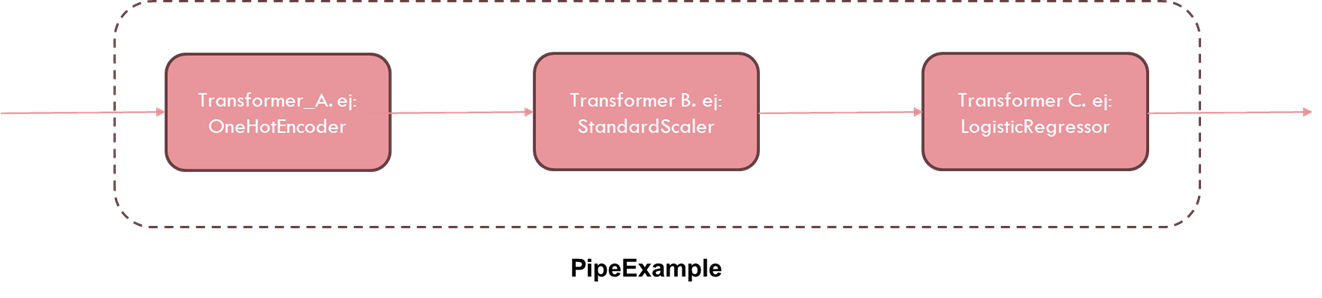

Si sobre el pipeline anterior ejecutamos el método `fit`:

```python
PipeExample.fit(X<,y>) # <,y> quiere decir que puede ser un fit solo con X (como un StandardScaler o una PCA) o con X, y (como una LogisticRegression u otros modelos supervisados)
```

* Equivale a `Transformer_C.fit(Transformer_B.fit_transform(Transformer_A.fit_transform(X<,y>)<,y>)<,y>)`:

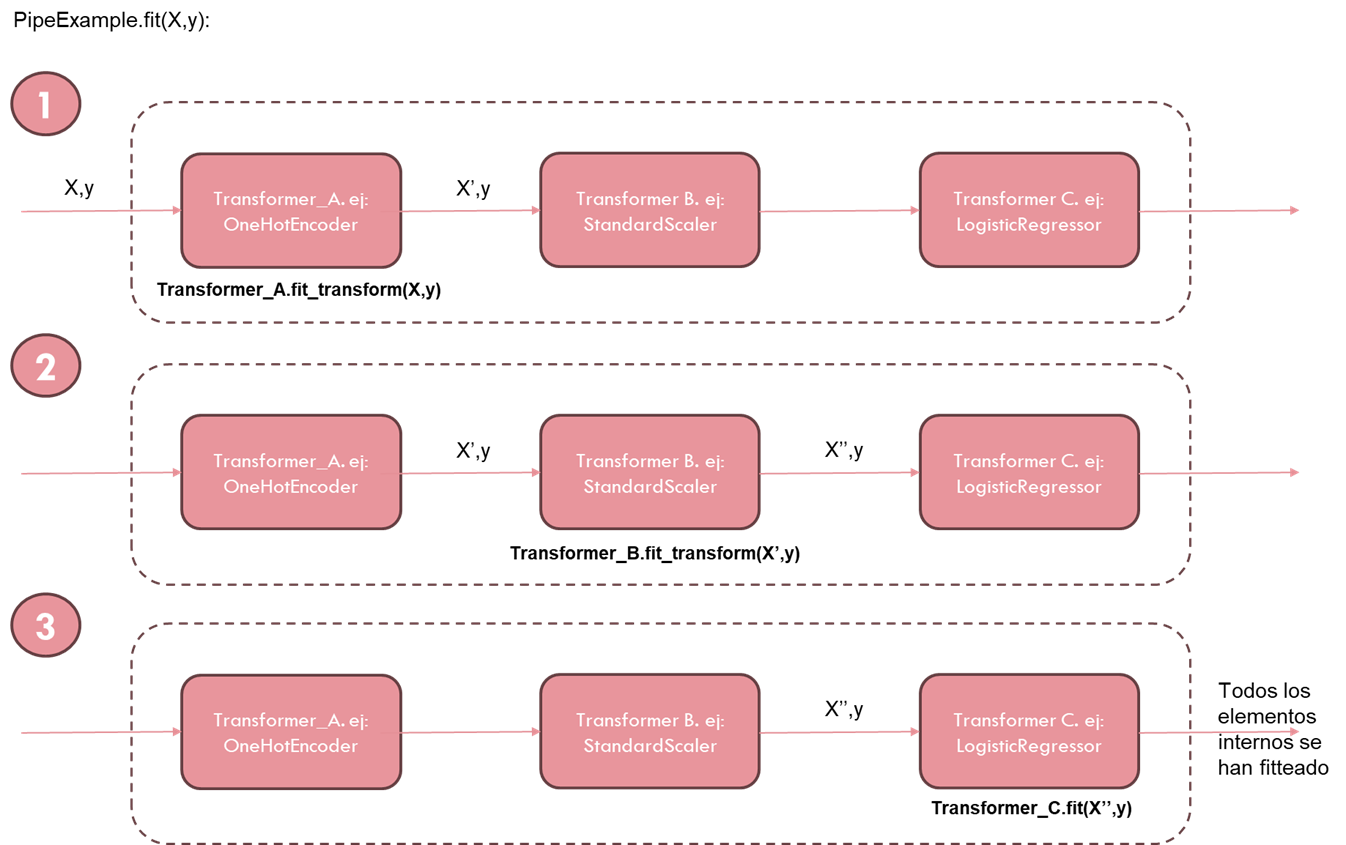

Si sobre el pipeline anterior ejecutamos el método `predict` (lo que implica que el último elemento del pipeline debe tener un método `predict`):

```python
PipeExample.predict(X)
```

* Equivale a `Transformer_C.predict(Transformer_B.transform(Transformer_A.transform(X)))`:

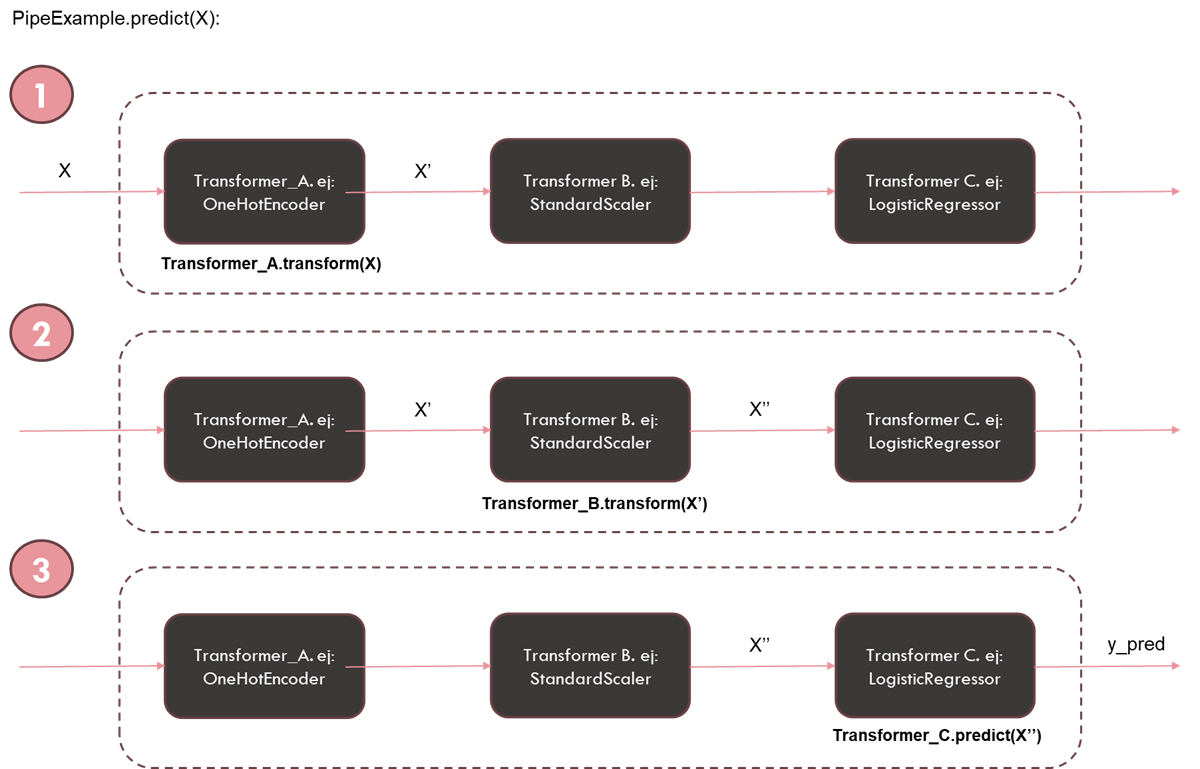

Como un pipeline cuyo último paso es un transformer es a su vez un transformer, **se puede meter como paso dentro de otro pipeline**. Lo único a tener en cuenta es que un pipeline que termina en un modelo (que no tiene `transform`) solo puede ir como **último** paso:

* `Pipeline([("preprocesado", pipe_de_transformers), ("modelo", pipe_que_acaba_en_modelo)])` -> OK
* `Pipeline([("modelo", pipe_que_acaba_en_modelo), ("otro", pipe_de_transformers)])` -> Error

### Nuestro primer pipeline

Empecemos por algo sencillo: imputar con la mediana y estandarizar las numéricas. Cada paso es una tupla `(nombre, transformer)`:

In [4]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
]).set_output(transform="pandas")

num_pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimatorto account fo

In [5]:
col_numericas = ["age", "sibsp", "parch", "fare"]

num_pipeline.fit_transform(X_train[col_numericas]).head()

,age,sibsp,parch,fare
838,0.158058,-0.476784,-0.484892,0.468278
621,0.922922,0.433324,-0.484892,0.392016
282,-1.065724,-0.476784,-0.484892,-0.440992
275,2.529135,0.433324,-0.484892,0.883533
217,0.922922,0.433324,-0.484892,-0.102404


Podemos acceder a cada paso por su nombre (o por su posición) para consultar lo que ha aprendido:

In [6]:
print(num_pipeline.named_steps["imputer"].statistics_)
print(num_pipeline[-1].mean_)

[29.      0.      0.     14.4542]
[29.93351124  0.5238764   0.35674157 32.29277149]


`make_pipeline` hace lo mismo sin tener que poner nombres (los genera a partir del nombre de la clase en minúsculas). Es más cómodo, pero los nombres explícitos se agradecen cuando el pipeline crece:

In [7]:
make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('simpleimputer', ...), ('standardscaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `add_indicator=True`.",True
,"add_indicator add_indicator: bool, default=FalseIf True, a :class:`MissingIndicator` transform will stack onto outputof the imputer's transform. This allows a predictive estimato

## `ColumnTransformer`: un tratamiento distinto para cada columna

En la aplicación práctica no tratamos igual todas las columnas:

| Columnas | Tratamiento |
|---|---|
| `age`, `sibsp`, `parch` | imputar con la mediana + estandarizar |
| `fare` | imputar con la mediana + logaritmo + estandarizar |
| `pclass` | imputar con la moda + estandarizar |
| `sex`, `who`, `embark_town` | imputar con la moda + one-hot |
| `adult_male`, `alone` | se quedan tal cual (ya son binarias) |

El `ColumnTransformer` aplica a cada grupo de columnas su propio transformer (o pipeline) y luego **concatena** los resultados. Cada elemento es una tupla `(nombre, transformer, columnas)` y, como transformer, además de cualquier transformer o pipeline podemos usar:
- `"drop"`: elimina esas columnas.
- `"passthrough"`: las deja pasar sin tocar.

Con `remainder` decidimos qué hacer con las columnas que no hemos mencionado: por defecto `"drop"` (se eliminan) o `"passthrough"` (se dejan tal cual).

In [8]:
from sklearn.compose import ColumnTransformer

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

log_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("log", FunctionTransformer(np.log1p, inverse_func=np.expm1, feature_names_out="one-to-one")),
    ("scaler", StandardScaler())
])

ord_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="if_binary", sparse_output=False, handle_unknown="ignore"))
])

preprocessing = ColumnTransformer([
    ("num", num_pipeline, ["age", "sibsp", "parch"]),
    ("log", log_pipeline, ["fare"]),
    ("ord", ord_pipeline, ["pclass"]),
    ("cat", cat_pipeline, ["sex", "who", "embark_town"]),
    ("bool", "passthrough", ["adult_male", "alone"])
], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer

Algunos detalles:
- `set_output(transform="pandas")` sobre el `ColumnTransformer` se propaga a todos los transformers de dentro. Para que funcione, el `OneHotEncoder` necesita `sparse_output=False` y el `FunctionTransformer` necesita `feature_names_out="one-to-one"`.
- `verbose_feature_names_out=False` evita que los nombres de las columnas de salida lleven delante el nombre del paso (`num__age`, `cat__sex_male`...).
- El orden de las columnas de salida es el orden de los pasos del `ColumnTransformer`, no el de `X_train`.

In [9]:
X_train_prep = preprocessing.fit_transform(X_train)
X_train_prep

,age,sibsp,parch,fare,pclass,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton,adult_male,alone
838,0.158058,-0.476784,-0.484892,1.127237,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
621,0.922922,0.433324,-0.484892,1.054454,-1.561052,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,False
282,-1.065724,-0.476784,-0.484892,-0.615381,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
275,2.529135,0.433324,-0.484892,1.452333,-1.561052,0.0,0.0,0.0,1.0,0.0,0.0,1.0,False,False
217,0.922922,0.433324,-0.484892,0.389838,-0.371042,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
594,0.540490,0.433324,-0.484892,0.352566,-0.371042,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,False
166,-0.071401,-0.476784,0.874332,1.100222,-1.561052,0.0,0.0,0.0,1.0,0.0,0.0,1.0,False,False
121,-0.071401,-0.476784,-0.484892,-0.767687,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
785,-0.377346,-0.476784,-0.484892,-0.862540,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True


In [10]:
X_train_prep.isna().sum().sum()

0

In [11]:
X_test_prep = preprocessing.transform(X_test)
X_test_prep.head()

,age,sibsp,parch,fare,pclass,sex_male,who_child,who_man,who_woman,embark_town_Cherbourg,embark_town_Queenstown,embark_town_Southampton,adult_male,alone
395,-0.606805,-0.476784,-0.484892,-0.796886,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
557,-0.071401,-0.476784,-0.484892,2.541485,-1.561052,1.0,0.0,1.0,0.0,1.0,0.0,0.0,True,True
563,-0.071401,-0.476784,-0.484892,-0.767687,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
21,0.311031,-0.476784,-0.484892,-0.320546,-0.371042,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True
444,-0.071401,-0.476784,-0.484892,-0.760634,0.818968,1.0,0.0,1.0,0.0,0.0,0.0,1.0,True,True


Hemos obtenido las mismas 14 columnas que en la aplicación práctica (en otro orden), pero con **un solo objeto** y **dos líneas**: un `fit_transform` para train y un `transform` para test. Y lo más importante: `preprocessing` ha guardado todo lo aprendido en train (medianas, modas, categorías, medias y desviaciones), así que podemos aplicarlo a cualquier dato nuevo.

Podemos navegar dentro del `ColumnTransformer` con `named_transformers_`:

In [12]:
preprocessing.named_transformers_["cat"]["onehot"].categories_

[array(['female', 'male'], dtype=object),
 array(['child', 'man', 'woman'], dtype=object),
 array(['Cherbourg', 'Queenstown', 'Southampton'], dtype=object)]

## Pipeline completo: preprocesado + modelo

Ahora encadenamos el preprocesado con un modelo. El resultado es un único objeto que recibe los datos **en crudo** y devuelve predicciones:

In [13]:
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline([
    ("preprocesado", preprocessing),
    ("modelo", LogisticRegression(max_iter=10000, random_state=42))
])

lr_pipeline.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocesado', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['pclass','sex','age',...,'adult_male','embark_town','alone']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('log', ...), ...]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbo

In [14]:
lr_pipeline.predict(X_test.head()) # datos en crudo, sin preprocesar

array([0, 1, 0, 0, 0], dtype=int64)

### Validación cruzada sin fugas

En la aplicación práctica hicimos la validación cruzada sobre un `X_train` ya preprocesado. Eso tiene una pequeña trampa: las medianas, modas, medias y desviaciones se calcularon con **todo** train, incluido el fold que luego usábamos para validar. Es una fuga de información pequeña, pero fuga al fin y al cabo.

Si pasamos el **pipeline** a `cross_val_score`, en cada fold se hace el `fit` del pipeline completo solo con los folds de entrenamiento, así que el fold de validación se comporta de verdad como datos nuevos:

In [15]:
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

modelos = {
    "Logistic Regression": LogisticRegression(max_iter=10000, random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "LightGBM": LGBMClassifier(random_state=42, verbose=-100),
    "CatBoost": CatBoostClassifier(random_state=42, verbose=False)
}

metricas_cv = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("preprocesado", preprocessing), ("modelo", modelo)])
    metricas_cv[nombre] = cross_val_score(pipe, X_train, y_train, cv=5, scoring="accuracy", n_jobs=-1).mean()

pd.Series(metricas_cv).sort_values(ascending=False)

CatBoost               0.820221
Logistic Regression    0.816054
LightGBM               0.804767
Random Forest          0.796326
dtype: float64

Los resultados son muy parecidos a los del baseline de la aplicación práctica (**CatBoost** sigue a la cabeza, con la **regresión logística** y **LightGBM** muy cerca), aunque no idénticos: ahora usamos 5 folds en lugar de 3 y, sobre todo, el preprocesado se aprende dentro de cada fold, así que la estimación es más honesta.

## Optimización de hiperparámetros con pipelines

Un pipeline se puede pasar a `GridSearchCV` o `RandomizedSearchCV` como cualquier otro modelo. Para referirnos a los hiperparámetros de un paso usamos su nombre seguido de **doble guion bajo** `__`:
- `modelo__C` -> el hiperparámetro `C` del paso `modelo`.
- `preprocesado__num__imputer__strategy` -> la `strategy` del paso `imputer`, del pipeline `num`, del `ColumnTransformer` `preprocesado`.

Esto nos permite **optimizar también el preprocesado**, algo imposible si lo hacemos fuera de la validación cruzada. Además, el propio paso `modelo` puede ser un hiperparámetro más: pasando una **lista de grids** podemos comparar varios modelos, cada uno con su grid, en una única búsqueda. Vamos a comparar los dos mejores modelos "ligeros" de la validación cruzada (dejamos fuera CatBoost solo para que la búsqueda no tarde demasiado).

Podemos ver todos los nombres disponibles con `get_params()`:

In [16]:
list(lr_pipeline.get_params().keys())[:25]

['memory',
 'steps',
 'transform_input',
 'verbose',
 'preprocesado',
 'modelo',
 'preprocesado__n_jobs',
 'preprocesado__remainder',
 'preprocesado__sparse_threshold',
 'preprocesado__transformer_weights',
 'preprocesado__transformers',
 'preprocesado__verbose',
 'preprocesado__verbose_feature_names_out',
 'preprocesado__num',
 'preprocesado__log',
 'preprocesado__ord',
 'preprocesado__cat',
 'preprocesado__bool',
 'preprocesado__num__memory',
 'preprocesado__num__steps',
 'preprocesado__num__transform_input',
 'preprocesado__num__verbose',
 'preprocesado__num__imputer',
 'preprocesado__num__scaler',
 'preprocesado__num__imputer__add_indicator']

In [17]:
pipe = Pipeline([
    ("preprocesado", preprocessing),
    ("modelo", LogisticRegression())
])

param_grid = [
    {
        "modelo": [LogisticRegression(max_iter=10000, random_state=42)],
        "modelo__C": [0.01, 0.1, 1, 10],
        "modelo__class_weight": [None, "balanced"],
        "preprocesado__num__imputer__strategy": ["mean", "median"]
    },
    {
        "modelo": [LGBMClassifier(random_state=42, verbose=-100)],
        "modelo__n_estimators": [100, 250],
        "modelo__learning_rate": [0.05, 0.1],
        "modelo__max_depth": [3, 6],
        "modelo__min_child_samples": [10, 20],
        "preprocesado__num__imputer__strategy": ["mean", "median"]
    }
]

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy", n_jobs=-1)
grid.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...egression())])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","[{'modelo': [LogisticRegre...ndom_state=42)], 'modelo__C': [0.01, 0.1, ...], 'modelo__class_weight': [None, 'balanced'], 'preprocesado__num__imputer__strategy': ['mean', 'median']}, {'modelo': [LGBMClassifie... verbose=-100)], 'modelo__learning_rate': [0.05, 0.1], 'modelo__max_depth': [3, 6], 'modelo__min_child_samples': [10, 20], ...}]"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'accuracy'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples

In [18]:
print("Mejor accuracy en CV:", grid.best_score_)
grid.best_params_

Mejor accuracy en CV: 0.8188220230473752


{'modelo': LGBMClassifier(random_state=42, verbose=-100),
 'modelo__learning_rate': 0.05,
 'modelo__max_depth': 3,
 'modelo__min_child_samples': 20,
 'modelo__n_estimators': 250,
 'preprocesado__num__imputer__strategy': 'median'}

In [19]:
resultados = pd.DataFrame(grid.cv_results_)
resultados["modelo"] = resultados["param_modelo"].astype(str).str.split("(").str[0]
resultados.groupby("modelo")["mean_test_score"].max().sort_values(ascending=False)

modelo
LGBMClassifier        0.818822
LogisticRegression    0.816054
Name: mean_test_score, dtype: float64

In [20]:
cols_resultados = ["modelo", "param_preprocesado__num__imputer__strategy", "mean_test_score"]
resultados.sort_values("rank_test_score")[cols_resultados].head(10)

,modelo,param_preprocesado__num__imputer__strategy,mean_test_score
23,LGBMClassifier,median,0.818822
39,LGBMClassifier,median,0.818792
8,LogisticRegression,mean,0.816054
9,LogisticRegression,median,0.816054
30,LGBMClassifier,mean,0.816005
37,LGBMClassifier,median,0.816005
12,LogisticRegression,mean,0.814646
36,LGBMClassifier,mean,0.814597
18,LGBMClassifier,mean,0.814567
13,LogisticRegression,median,0.813237


**LightGBM** (árboles poco profundos, `learning_rate` 0.05 y 250 árboles) obtiene la mejor accuracy en CV (0.819), pero la **regresión logística** se queda muy cerca (0.816): es prácticamente un empate. La estrategia de imputación de las numéricas (media o mediana) apenas influye. Nos quedamos con el mejor en CV, que es lo que hace `GridSearchCV` automáticamente.

## Evaluación contra test

`best_estimator_` es el pipeline completo (preprocesado + modelo) reentrenado con todo train con los mejores hiperparámetros. Le pasamos `X_test` **en crudo**:

In [21]:
best_pipeline = grid.best_estimator_

y_pred = best_pipeline.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.92      0.88       103
           1       0.88      0.78      0.83        76

    accuracy                           0.86       179
   macro avg       0.86      0.85      0.85       179
weighted avg       0.86      0.86      0.86       179



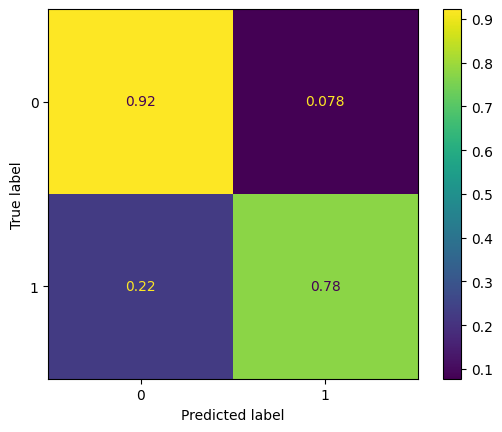

In [22]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true");

El pipeline obtiene una accuracy de 0.86 en test, algo **mejor** que en validación cruzada (0.82). No es que el modelo haya mejorado: con solo 179 pasajeros en test, unos pocos aciertos de más mueven bastante la métrica. Lo importante es que no hay síntomas de sobreajuste y que, respecto al modelo de la aplicación práctica, detecta mejor a los supervivientes (recall 0.78).

## Guardar el pipeline

Todo lo que necesitamos para predecir (lo aprendido por los transformers y por el modelo) está dentro de `best_pipeline`, así que basta con guardar **un único archivo**. Lo hacemos con `joblib`, la opción más habitual con sklearn (también se podría usar `pickle`, que funciona igual: `pickle.dump(objeto, archivo)`):

In [23]:
os.makedirs("../modelos", exist_ok=True)

joblib.dump(best_pipeline, "../modelos/titanic_pipeline.joblib")

['../modelos/titanic_pipeline.joblib']

#### **¡Enhorabuena! Ya puedes pasar al cuaderno Pipelines II, donde usaremos el pipeline guardado para predecir datos nuevos.**